# **Критерии оценки практической экзаменационной работы**
1. Выполнение задания. Студент должен написать работающий код, выполняющий действия, указанные в экзаменационной задаче. Код не должен выполняться с ошибками.
2. Наличие выводов. Ответ должен содержать текстовые либо устные замечания, поясняющие каждый шаг работы студента: что делается, зачем и какую информацию это нам дает. Оценивается полнота и адекватность выводов.
3. Дополнительные выводы и действия. Оцениваются все дополнительные комментарии и операции, более полно раскрывающие процесс, описанный в экзаменационной задаче.


# **Примерные задачи для подготовки к экзамену**

## **[✓] 1. Загрузить встроенный в библиотеку sklearn датасет “Ирисы”. Несколькими способами, в том числе графическим, убедиться в отсутствии пропущенных значений.**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [ ]:
# Загружаем датасет
iris = load_iris()

In [ ]:
# Преобразуем в DataFrame
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target  # добавим столбец с метками классов

In [ ]:
# Проверка на NaN/None
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [ ]:
# Через info entries == Non-Null Count
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


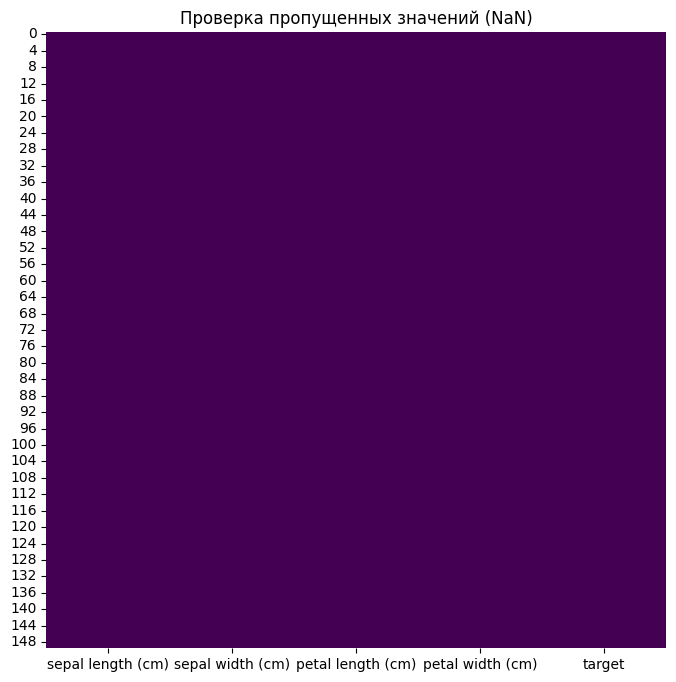

In [ ]:
# Графический способ
plt.figure(figsize=(8, 8))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Проверка пропущенных значений (NaN)")

plt.show()

## **2. Загрузить встроенный в библиотеку sklearn датасет “Диабет”. Визуализировать распределение четырех любых признаков, входящих в датасет. Сделать содержательные выводы по полученным данным.**

In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Загрузка датасета
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

In [ ]:
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


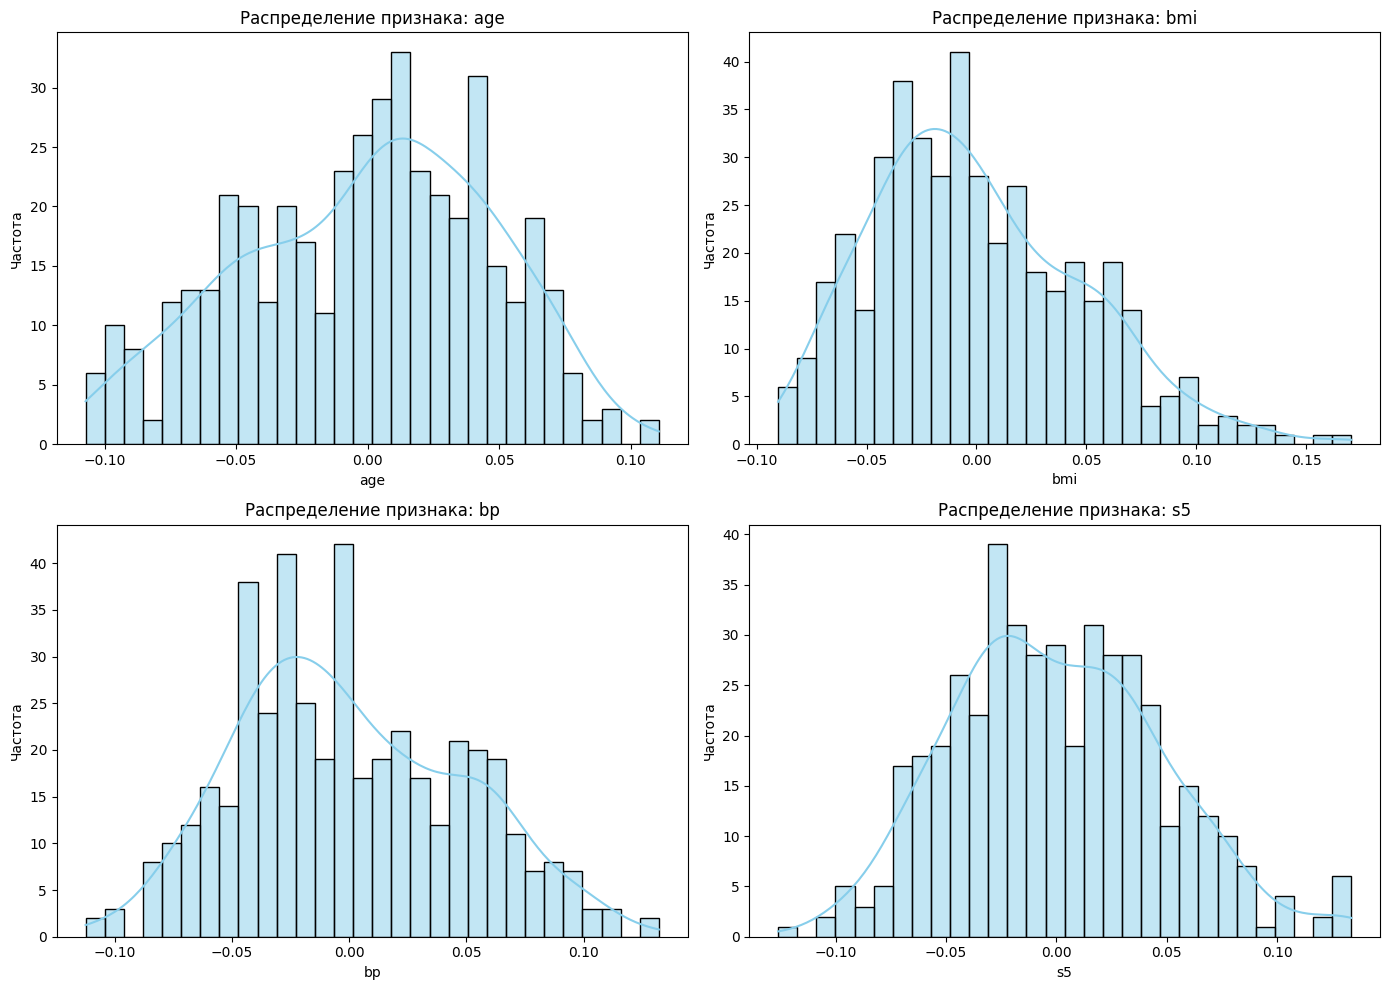

In [ ]:
features_to_plot = ['age', 'bmi', 'bp', 's5']

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features_to_plot):
    plt.subplot(2, 2, i+1)
    sns.histplot(X[feature], kde=True, bins=30, color='skyblue')
    plt.title(f'Распределение признака: {feature}')
    plt.xlabel(feature)
    plt.ylabel('Частота')

plt.tight_layout()
plt.show()

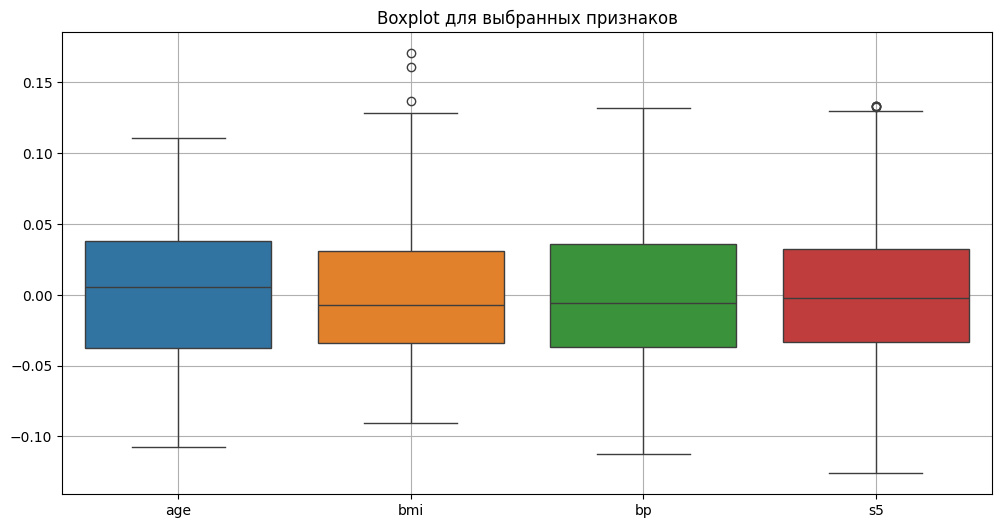

In [ ]:
# Дополнительно можно визуализорвать боксплоты
plt.figure(figsize=(12, 6))
sns.boxplot(data=X[features_to_plot])
plt.title('Boxplot для выбранных признаков')
plt.grid()
plt.show()

**Вывод:**

## **[✓] 3. Загрузить встроенный в библиотеку sklearn датасет “Рак груди”. Построить модель бинарной классификации любым методом. Вывести несколько первых теоретических и эмпирических значений целевой переменной. Сделать выводы по полученным результатам.**

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

In [ ]:
# Загружаем датасет
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

In [ ]:
# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

In [ ]:
# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Обучение модели логистической регрессии
model = LogisticRegression(max_iter=10000, random_state=2)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=10000, random_state=2)

In [ ]:
# Предсказания
y_pred = model.predict(X_test_scaled)

In [ ]:
# Сравнение первых 10 значений целевой переменной
comparison = pd.DataFrame({
    "Теоретическое (предсказание)": y_pred[:10],
    "Эмпирическое (реальное)": y_test.values[:10]
})

display(comparison)

,Теоретическое (предсказание),Эмпирическое (реальное)
0,1,1
1,0,1
2,0,0
3,1,1
4,0,0
5,0,0
6,0,0
7,1,1
8,1,1
9,0,0


In [ ]:
print("Accuracy на тестовой выборке:", accuracy_score(y_test, y_pred))

Accuracy на тестовой выборке: 0.9824561403508771


**Вывод: Точность на тустовой выборке составила ~ $0.98$, что говорит о высокой предсказательной способности модели.**

## **[✓] 4. Загрузить встроенный в библиотеку sklearn датасет “Вина”. Построить линейную модель обучения с учителем, вывести и проинтерпретировать коэффициенты линейной модели. Коэффициенты должны выводиться вместе с названием соответствующего признака.**


In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

In [ ]:
# Загружаем данные
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

In [ ]:
# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5)

In [ ]:
# Масштабируем признаки
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [ ]:
# Обучение линейной модели - Логистической регрессии
model = LogisticRegression(max_iter=10000, random_state=43)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=10000, random_state=43)

In [ ]:
# Преобразуем коэффициенты в DataFrame
coef_df = pd.DataFrame(model.coef_, columns=wine.feature_names)

# Добавим название классов
coef_df['Класс вина'] = [f"Класс {i}" for i in model.classes_]

# Переставим столбцы для красоты
coef_df = coef_df[['Класс вина'] + wine.feature_names]

display(coef_df)

,Класс вина,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,Класс 0,0.789477,0.065504,0.251755,-0.817562,0.087324,0.234822,0.598856,-0.288502,0.173297,0.149553,0.123993,0.588135,1.030315
1,Класс 1,-0.914456,-0.352535,-0.690882,0.527096,-0.037674,-0.028111,0.417874,0.187927,0.199980,-1.046575,0.621575,0.025865,-1.082715
2,Класс 2,0.124979,0.287031,0.439127,0.290465,-0.049650,-0.206711,-1.016730,0.100576,-0.373276,0.897022,-0.745568,-0.614000,0.052400


Коэффициенты линейной модели (в логистической регрессии) показывают, как влияет изменение каждого признака на **вероятность** принадлежности к каждому классу:

Положительный коэффициент $\rightarrow$ увеличение этого признака увеличивает вероятность принадлежности к классу.

Отрицательный коэффициент $\rightarrow$ уменьшает вероятность.

Наример, если у признака flavanoids коэффициент для Класса $0$ равен ~ $0.6$, это значит, что чем больше флавоноидов, тем выше вероятность, что это вино относится к Классу $0$ (при прочих равных условиях).

## **[✓] 5. Загрузить встроенный в библиотеку sklearn датасет “Калифорния”. Построить модель регрессии любым методом. Оптимизировать гиперпараметры модели при помощи поиска по сетке. Сделать выводы.**

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score,\
                            root_mean_squared_error,\
                            mean_absolute_error,\
                            mean_absolute_percentage_error

In [ ]:
# Загружаем данные
data = fetch_california_housing()
X, y = data.data, data.target

In [ ]:
# Разеление на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)

In [ ]:
# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Базовая модель
model = SVR()

In [ ]:
# Сетка гиперпараметров
param_grid = {
    'kernel': ['rbf'],              # Радиальная функция – наиболее универсальная
    'C': [1, 10, 100],              # Штраф за ошибку
    'gamma': ['scale', 0.01, 0.1],  # Параметр для RBF-ядра
    'epsilon': [0.1, 0.2, 0.5],     # Размер зоны, в пределах которой ошибка не штрафуется
}

In [ ]:
# GridSearchCV
grid_search = GridSearchCV(model, param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=1)
grid_search.fit(X_train_scaled, y_train)

Fitting 3 folds for each of 27 candidates, totalling 81 fits


GridSearchCV(cv=3, estimator=SVR(), n_jobs=-1,
             param_grid={'C': [1, 10, 100], 'epsilon': [0.1, 0.2, 0.5],
                         'gamma': ['scale', 0.01, 0.1], 'kernel': ['rbf']},
             scoring='r2', verbose=1)

In [ ]:
# Предсказания
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_scaled)

In [ ]:
# Метрики
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

In [ ]:
print("Лучшие параметры:", grid_search.best_params_)
print(f"R^2:   {r2:.4f}")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"MAPE:  {mape:.2f}%")

Лучшие параметры: {'C': 10, 'epsilon': 0.2, 'gamma': 'scale', 'kernel': 'rbf'}
R^2:   0.7657
MAE:   0.3696
RMSE:  0.5610
MAPE:  0.20%


**Были найдены оптимальные пармаетры на сетке. Модель неплохо обучилась.**

## **[✓] 6. Загрузить встроенный в библиотеку sklearn датасет “Ирисы”. Построить модель множественной классификации любым методом. Оценить ее эффективность при помощи кросс-валидации. Сделать выводы.**

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np

In [ ]:
# Загружаем датасет
iris = load_iris()
X, y = iris.data, iris.target

In [ ]:
# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
model = LogisticRegression(max_iter=10_000, random_state=7)

In [ ]:
# Кросс-валидация (5 фолдов)
scores = cross_val_score(model, X_scaled, y, cv=5, scoring='accuracy')

In [ ]:
# Вывод результатов
print("Оценки точности на каждой из 5 фолдов:", scores)
print("Средняя точность модели:", np.mean(scores))

Оценки точности на каждой из 5 фолдов: [0.96666667 1.         0.93333333 0.9        1.        ]
Средняя точность модели: 0.9600000000000002


**Вывод: Средняя точность модели на кросс-валидации составляет 0.96, что говорит о высокой эффективности. Кросс-валидация позволяет убедиться, что модель обобщается, а не просто переобучена на конкретной выборке.**

## **[✓] 7. Загрузить встроенный в библиотеку sklearn датасет “Диабет”. Построить модель регрессии по методу опорных векторов с линейным ядром. Оценить ее эффективность по метрикам  r2, mae, rmse, mape. Сделать выводы о применимости модели.**

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score,\
                            mean_absolute_error,\
                            mean_squared_error,\
                            mean_absolute_percentage_error

In [ ]:
# Загружаем данные
data = load_diabetes()
X, y = data.data, data.target

In [ ]:
# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=27)

In [ ]:
# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Модель SVM для регрессии с линейным ядром
model = SVR(kernel='linear')
model.fit(X_train_scaled, y_train)

SVR(kernel='linear')

In [ ]:
# Предсказания
y_pred = model.predict(X_test_scaled)

In [ ]:
# Метрики
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred)

In [ ]:
# Вывод
print(f"R^2: {r2:.4f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

R^2: 0.4072
MAE: 40.97
RMSE: 51.57
MAPE: 0.29%


**$R^2$ довольно низкий, модель не очень хорошо объясняет дисперсию целевой переменной; $RMSE$ заметно отличается от $MAE$, так как $RMSE$ более чувствительна к выбросам; $MAPE$ показывает, в среднем на сколько процентов предсказания отклоняются от истинных значений. Вывод: Модель работает, но не идеально — линейное ядро может не захватывать сложные зависимости в данных.**

## **[✓] 8. Загрузить встроенный в библиотеку sklearn датасет “Рак груди”. Построить модель бинарной линейной классификации. Задать значения аргументов конструктора объекта модели, отличающиеся от значений по умолчанию. Пояснить смысл каждого аргумента.**

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
# Загружаем датасет
data = load_breast_cancer()
X, y = data.data, data.target

In [ ]:
# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
# Масштабирование данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Создание модели с параметрами, отличающимися от стандартных
model = LogisticRegression(
    penalty='l1',           # L1-регуляризация (по умолчанию 'l2')
    C=0.5,                  # Обратная сила регуляризации (чем больше C, тем меньше регуляризация) (по умолчанию 1.0)
    solver='liblinear',     # Решатель, подходящий для L1-регуляризации
    max_iter=10_000,           # Максимальное число итераций (по умолчанию 100)
    random_state=26         # Фиксация генератора случайных чисел для воспроизводимости
)

model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.5, max_iter=10000, penalty='l1', random_state=26,
                   solver='liblinear')

In [ ]:
# Предсказания
y_pred = model.predict(X_test_scaled)

In [ ]:
# Метрика Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy:.4f}")

Точность модели: 0.9561


## **[✓] 9. Загрузить встроенный в библиотеку sklearn датасет “Вина”. Построить модель множественной классификации по методу опорных векторов с полиномиальным ядром. Оценить ее эффективность по метрикам accuracy, precision, recall, f1. Сделать выводы о применимости модели.**

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,\
                            precision_score,\
                            recall_score,\
                            f1_score,\
                            classification_report

In [ ]:
# Загружаем данные
data = load_wine()
X, y = data.data, data.target

In [ ]:
# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [ ]:
# Масштабирование признаков (важно для SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Обучаем модель SVM с полиномиальным ядром
model = SVC(kernel='poly', degree=3, random_state=42)
model.fit(X_train_scaled, y_train)

SVC(kernel='poly', random_state=42)

In [ ]:
# Предсказания
y_pred = model.predict(X_test_scaled)

In [ ]:
# Метрики
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')  # для мультикласса
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

In [ ]:
# Вывод метрик
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.9722
Precision: 0.9762
Recall:    0.9744
F1-score:  0.9743


In [ ]:
# Подробный отчёт
print("\nОтчёт классификации:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Отчёт классификации:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        10
     class_1       0.93      1.00      0.96        13
     class_2       1.00      0.92      0.96        13

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



**Вывод: SVC с полиномиальным ядром (степени $3$) может хорошо работает на мультиклассовых задачах, особенно при наличии нелинейных границ между классами. В датасете “Вина” три класса, и признаки хорошо масштабируются — поэтому модель SVM показывает высокие значения accuracy, precision, recall и f1-score (близкие к $1$).**

## **[✓] 10. Загрузить встроенный в библиотеку sklearn датасет “Калифорния”. Построить модель регрессии с регуляризацией. Задать значения аргументов конструктора объекта модели, отличающиеся от значений по умолчанию. Пояснить смысл каждого аргумента.**

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score,\
                            root_mean_squared_error,\
                            mean_absolute_error,\
                            mean_absolute_percentage_error

In [ ]:
# Загрузка данных
data = fetch_california_housing()
X, y = data.data, data.target

In [ ]:
# Деление на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
# Масштабирование данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Обучение модели
ridge = Ridge(
    alpha=10.0,          # Коэффициент регуляризации (чем больше, тем сильнее штрафуются веса модели за величину)
    solver='saga',       # Итеративный решатель, подходящий для больших выборок и поддерживающий регуляризацию
    fit_intercept=True,  # Добавляет свободный член (перехват) в модель
    max_iter=5000,       # Максимальное количество итераций для сходимости
    tol=1e-3,            # Порог точности — если улучшение меньше этого значения, обучение прекращается
    random_state=2       # Фиксация случайности для воспроизводимости
    )
ridge.fit(X_train_scaled, y_train)

Ridge(alpha=10.0, max_iter=5000, random_state=2, solver='saga', tol=0.001)

In [ ]:
# Предсказания
y_pred = ridge.predict(X_test_scaled)

In [ ]:
# Метрики
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

In [ ]:
print(f"R^2:   {r2:.4f}")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"MAPE:  {mape:.2f}%")

R^2:   0.5943
MAE:   0.5349
RMSE:  0.7274
MAPE:  0.32%
